# Telco Customer Churn: Analysis and Prediction
**Problem:** Which customers are most likely to leave, why, and how much revenue is at risk?
**Data:** Telco Customer Churn (7,043 customers, 21 columns, target `Churn`).
**Method:** Cleaning (pandas) -> SQL (SQLite) -> EDA -> churn model (logistic regression, random forest) -> risk tiers for a dashboard.

## 1. Load and inspect the raw file

In [1]:
import glob
import numpy as np, pandas as pd
patterns = ["/kaggle/input/**/*Telco*Churn*.csv", "/mnt/user-data/uploads/*Telco*Churn*.csv", "./*Telco*Churn*.csv"]
raw = pd.read_csv([f for p in patterns for f in glob.glob(p, recursive=True)][0])
print(raw.shape)
raw.info()
print("Missing values:", raw.isnull().sum().sum())
print("Blank strings in TotalCharges:", (raw["TotalCharges"].astype(str).str.strip() == "").sum())
print(raw["Churn"].value_counts(normalize=True).round(3))
raw.head()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the data
This cell is the file `01_clean_telco.py`. Every change is printed.
- 11 blank `TotalCharges` values (all customers with tenure 0, none churned) are set to 0: they have not been billed yet.
- `Churn` becomes `churn_flag` (1/0); `SeniorCitizen` gets a readable label.
- New columns: `num_addons`, `tenure_band`, `monthly_revenue_lost`.

In [2]:
"""
01_clean_telco.py
Cleans the Telco Customer Churn dataset and writes telco_clean.csv.
Every change is printed so it can be copied into the README.

Usage on Kaggle: set RAW_PATH to the file shown in the notebook sidebar.
"""
import glob
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- load
patterns = ["/kaggle/input/**/*Telco*Churn*.csv",        # Kaggle
            "/mnt/user-data/uploads/*Telco*Churn*.csv",  # this chat environment
            "./*Telco*Churn*.csv"]                       # current folder
files = [f for p in patterns for f in glob.glob(p, recursive=True)]
if not files:
    raise FileNotFoundError("Telco CSV not found - set RAW_PATH to the path in the Kaggle sidebar.")
RAW_PATH = files[0]
df = pd.read_csv(RAW_PATH)
log = []
log.append(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")

# ---------------------------------------------------------------- 1. whitespace
# Strip stray spaces from every text column (this is what hid the blanks in TotalCharges).
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].str.strip()

# ---------------------------------------------------------------- 2. duplicates
n_dup_rows = int(df.duplicated().sum())
n_dup_ids = int(df["customerID"].duplicated().sum())
df = df.drop_duplicates()
log.append(f"Duplicate rows: {n_dup_rows}; duplicate customerIDs: {n_dup_ids} (nothing removed)")

# ---------------------------------------------------------------- 3. TotalCharges
# TotalCharges is text because 11 rows contain a blank string.
blank_mask = df["TotalCharges"] == ""
n_blank = int(blank_mask.sum())
all_zero_tenure = bool((df.loc[blank_mask, "tenure"] == 0).all())
none_churned = bool((df.loc[blank_mask, "Churn"] == "No").all())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace("", np.nan))
# These customers have tenure 0, i.e. they have not been billed yet, so the true total is 0.
# We keep the rows (they are real, active customers) and set TotalCharges to 0.
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
log.append(f"TotalCharges: {n_blank} blank rows converted to 0 "
           f"(all tenure=0: {all_zero_tenure}; none churned: {none_churned})")

# ---------------------------------------------------------------- 4. target
df["churn_flag"] = df["Churn"].map({"Yes": 1, "No": 0}).astype(int)   # 1/0 for maths and models
log.append("Churn mapped to churn_flag (Yes=1, No=0); original Churn column kept as a label")

# ---------------------------------------------------------------- 5. SeniorCitizen
# It is 0/1 while every other yes/no column is text. Keep the number, add a readable label.
df["senior_label"] = df["SeniorCitizen"].map({1: "Senior", 0: "Non-senior"})

# ---------------------------------------------------------------- 6. new features
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
# "No internet service" is treated as "No" when counting add-ons.
df["num_addons"] = (df[addon_cols] == "Yes").sum(axis=1)

df["tenure_band"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["1. 0-12 months", "2. 13-24 months",
                                   "3. 25-48 months", "4. 49-72 months"]).astype(str)

# Monthly revenue that walked away with churned customers (0 for customers who stayed).
df["monthly_revenue_lost"] = df["MonthlyCharges"] * df["churn_flag"]
log.append("Added columns: churn_flag, senior_label, num_addons, tenure_band, monthly_revenue_lost")

# ---------------------------------------------------------------- 7. checks
assert df["customerID"].is_unique
assert df.isnull().sum().sum() == 0
assert df["TotalCharges"].dtype.kind == "f"
log.append(f"Final shape: {df.shape}; missing values left: {int(df.isnull().sum().sum())}; "
           f"churn rate: {df['churn_flag'].mean()*100:.1f}%")

df.to_csv("telco_clean.csv", index=False)
print("\n".join(log))


Loaded 7043 rows x 21 columns
Duplicate rows: 0; duplicate customerIDs: 0 (nothing removed)
TotalCharges: 11 blank rows converted to 0 (all tenure=0: True; none churned: True)
Churn mapped to churn_flag (Yes=1, No=0); original Churn column kept as a label
Added columns: churn_flag, senior_label, num_addons, tenure_band, monthly_revenue_lost
Final shape: (7043, 26); missing values left: 0; churn rate: 26.5%


## 3. SQL analysis (SQLite inside the notebook)
The 11 queries below are the file `02_queries.sql`.

In [3]:
import sqlite3
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
conn = sqlite3.connect(":memory:")
df.to_sql("customers", conn, index=False, if_exists="replace")
def q(sql): return pd.read_sql(sql, conn)

**Q1: Overall churn rate and monthly revenue at risk**

In [4]:
q("""
SELECT COUNT(*)                                             AS customers,
       SUM(churn_flag)                                      AS churned,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1)         AS churn_pct,
       ROUND(SUM(monthly_revenue_lost), 0)                  AS monthly_revenue_lost,
       ROUND(SUM(MonthlyCharges), 0)                        AS total_monthly_revenue,
       ROUND(100.0 * SUM(monthly_revenue_lost) / SUM(MonthlyCharges), 1) AS pct_revenue_lost
FROM customers;
""")

,customers,churned,churn_pct,monthly_revenue_lost,total_monthly_revenue,pct_revenue_lost
0,7043,1869,26.5,139131.0,456117.0,30.5


**Q2: Churn by contract type**

In [5]:
q("""
SELECT Contract,
       COUNT(*)                                     AS customers,
       SUM(churn_flag)                              AS churned,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct,
       ROUND(AVG(MonthlyCharges), 1)                AS avg_monthly
FROM customers
GROUP BY Contract
ORDER BY churn_pct DESC;
""")

,Contract,customers,churned,churn_pct,avg_monthly
0,Month-to-month,3875,1655,42.7,66.4
1,One year,1473,166,11.3,65.0
2,Two year,1695,48,2.8,60.8


**Q3: Churn by internet service**

In [6]:
q("""
SELECT InternetService,
       COUNT(*)                                     AS customers,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct,
       ROUND(AVG(MonthlyCharges), 1)                AS avg_monthly
FROM customers
GROUP BY InternetService
ORDER BY churn_pct DESC;
""")

,InternetService,customers,churn_pct,avg_monthly
0,Fiber optic,3096,41.9,91.5
1,DSL,2421,19.0,58.1
2,No,1526,7.4,21.1


**Q4: Payment methods ranked by churn rate (window function)**

In [7]:
q("""
SELECT PaymentMethod,
       COUNT(*)                                     AS customers,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct,
       RANK() OVER (ORDER BY 1.0 * SUM(churn_flag) / COUNT(*) DESC) AS churn_rank
FROM customers
GROUP BY PaymentMethod;
""")

,PaymentMethod,customers,churn_pct,churn_rank
0,Electronic check,2365,45.3,1
1,Mailed check,1612,19.1,2
2,Bank transfer (automatic),1544,16.7,3
3,Credit card (automatic),1522,15.2,4


**Q5: Churn by tenure band**

In [8]:
q("""
SELECT tenure_band,
       COUNT(*)                                     AS customers,
       SUM(churn_flag)                              AS churned,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct
FROM customers
GROUP BY tenure_band
ORDER BY tenure_band;
""")

,tenure_band,customers,churned,churn_pct
0,1. 0-12 months,2186,1037,47.4
1,2. 13-24 months,1024,294,28.7
2,3. 25-48 months,1594,325,20.4
3,4. 49-72 months,2239,213,9.5


**Q6: Monthly charges and tenure, churned vs retained**

In [9]:
q("""
SELECT Churn,
       COUNT(*)                       AS customers,
       ROUND(AVG(MonthlyCharges), 1)  AS avg_monthly_charge,
       ROUND(AVG(tenure), 1)          AS avg_tenure_months,
       ROUND(AVG(TotalCharges), 0)    AS avg_total_charges
FROM customers
GROUP BY Churn;
""")

,Churn,customers,avg_monthly_charge,avg_tenure_months,avg_total_charges
0,No,5174,61.3,37.6,2550.0
1,Yes,1869,74.4,18.0,1532.0


**Q7: Churn by number of add-on services (CTE)**

In [10]:
q("""
WITH addons AS (
  SELECT customerID, num_addons, churn_flag
  FROM customers
  WHERE InternetService <> 'No'
)
SELECT num_addons,
       COUNT(*)                                     AS customers,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct
FROM addons
GROUP BY num_addons
ORDER BY num_addons;
""")

,num_addons,customers,churn_pct
0,0,693,52.2
1,1,966,45.8
2,2,1033,35.8
3,3,1118,27.4
4,4,852,22.3
5,5,571,12.4
6,6,284,5.3


**Q8: Top risk segments: contract x internet service (at least 100 customers)**

In [11]:
q("""
SELECT Contract, InternetService,
       COUNT(*)                                     AS customers,
       SUM(churn_flag)                              AS churned,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct,
       ROUND(SUM(monthly_revenue_lost), 0)          AS monthly_revenue_lost
FROM customers
GROUP BY Contract, InternetService
HAVING COUNT(*) >= 100
ORDER BY churn_pct DESC;
""")

,Contract,InternetService,customers,churned,churn_pct,monthly_revenue_lost
0,Month-to-month,Fiber optic,2128,1162,54.6,100482.0
1,Month-to-month,DSL,1223,394,32.2,18367.0
2,One year,Fiber optic,539,104,19.3,10572.0
3,Month-to-month,No,524,99,18.9,1998.0
4,One year,DSL,570,53,9.3,3356.0
5,Two year,Fiber optic,429,31,7.2,3246.0
6,One year,No,364,9,2.5,190.0
7,Two year,DSL,628,12,1.9,806.0
8,Two year,No,638,5,0.8,114.0


**Q9: Churn among internet customers by tech support and online security (subquery)**

In [12]:
q("""
SELECT TechSupport, OnlineSecurity,
       COUNT(*)                                     AS customers,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct
FROM (SELECT * FROM customers WHERE InternetService <> 'No')
GROUP BY TechSupport, OnlineSecurity
ORDER BY churn_pct DESC;
""")

,TechSupport,OnlineSecurity,customers,churn_pct
0,No,No,2553,49.0
1,Yes,No,945,22.3
2,No,Yes,920,21.3
3,Yes,Yes,1099,9.0


**Q10: Share of all churners by contract and cumulative share (window functions)**

In [13]:
q("""
SELECT Contract,
       SUM(churn_flag) AS churned,
       ROUND(100.0 * SUM(churn_flag) / SUM(SUM(churn_flag)) OVER (), 1) AS pct_of_all_churners,
       ROUND(100.0 * SUM(SUM(churn_flag)) OVER (ORDER BY SUM(churn_flag) DESC)
             / SUM(SUM(churn_flag)) OVER (), 1) AS cumulative_pct
FROM customers
GROUP BY Contract
ORDER BY churned DESC;
""")

,Contract,churned,pct_of_all_churners,cumulative_pct
0,Month-to-month,1655,88.6,88.6
1,One year,166,8.9,97.4
2,Two year,48,2.6,100.0


**Q11: Demographics: senior citizens, partners and dependents**

In [14]:
q("""
SELECT senior_label, Partner, Dependents,
       COUNT(*)                                     AS customers,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 1) AS churn_pct
FROM customers
GROUP BY senior_label, Partner, Dependents
HAVING COUNT(*) >= 100
ORDER BY churn_pct DESC;
""")

,senior_label,Partner,Dependents,customers,churn_pct
0,Senior,No,No,561,49.2
1,Senior,Yes,No,490,36.3
2,Non-senior,No,No,2719,31.2
3,Non-senior,No,Yes,353,21.2
4,Non-senior,Yes,No,1163,20.8
5,Non-senior,Yes,Yes,1666,13.7


## 4. Exploratory charts

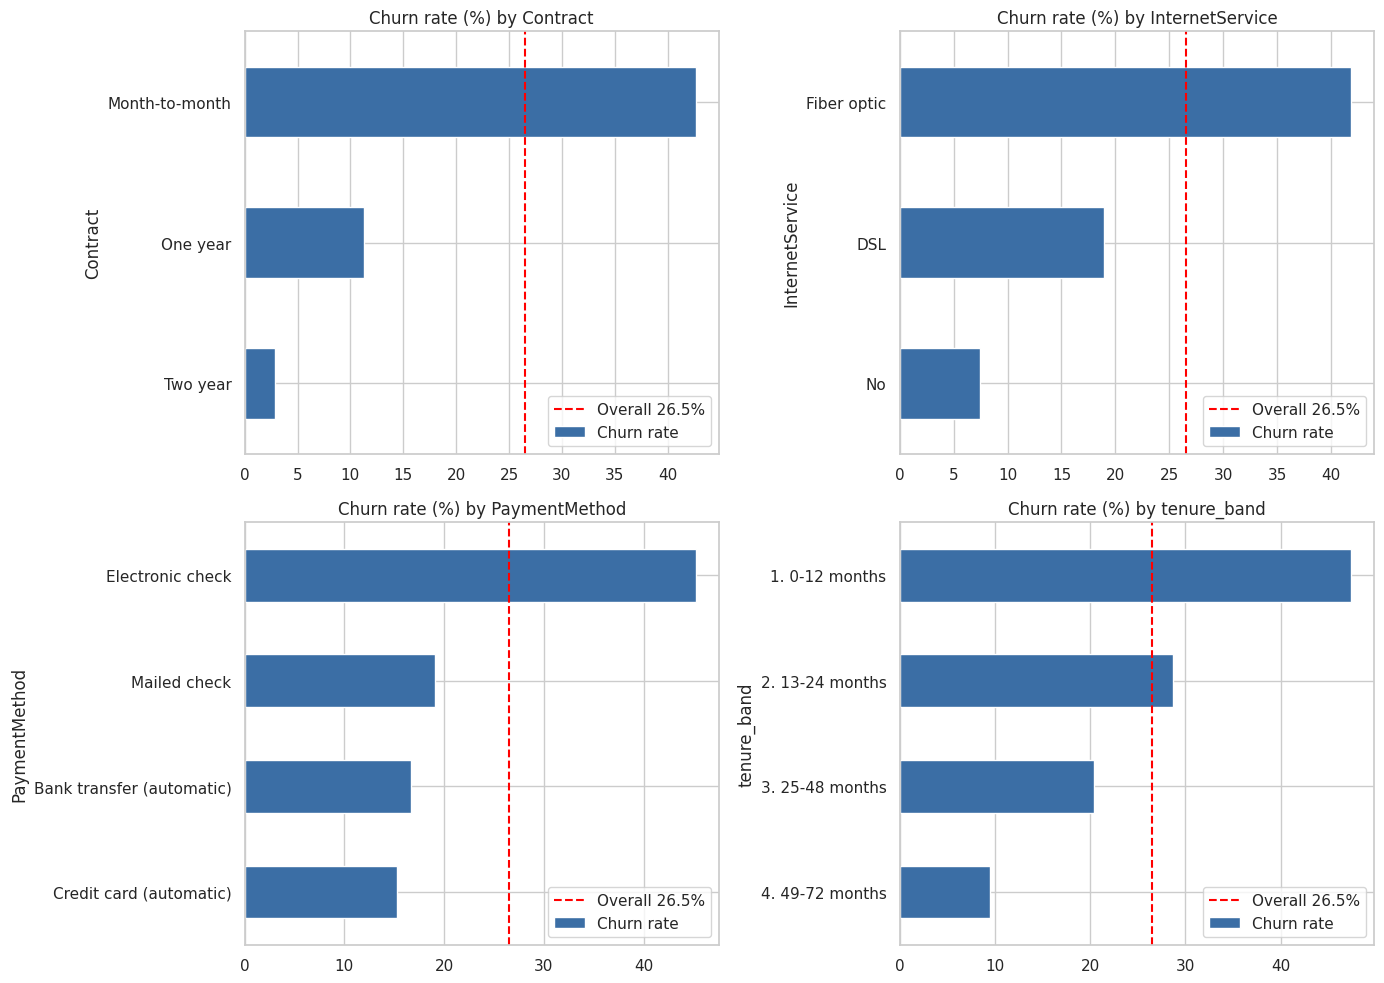

In [15]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
overall = df["churn_flag"].mean() * 100
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for a, col in zip(ax.ravel(), ["Contract", "InternetService", "PaymentMethod", "tenure_band"]):
    (df.groupby(col)["churn_flag"].mean() * 100).sort_values().plot.barh(ax=a, color="#3b6ea5", label="Churn rate")
    a.axvline(overall, color="red", ls="--", label=f"Overall {overall:.1f}%")
    a.set_title(f"Churn rate (%) by {col}"); a.legend()
plt.tight_layout(); plt.show()

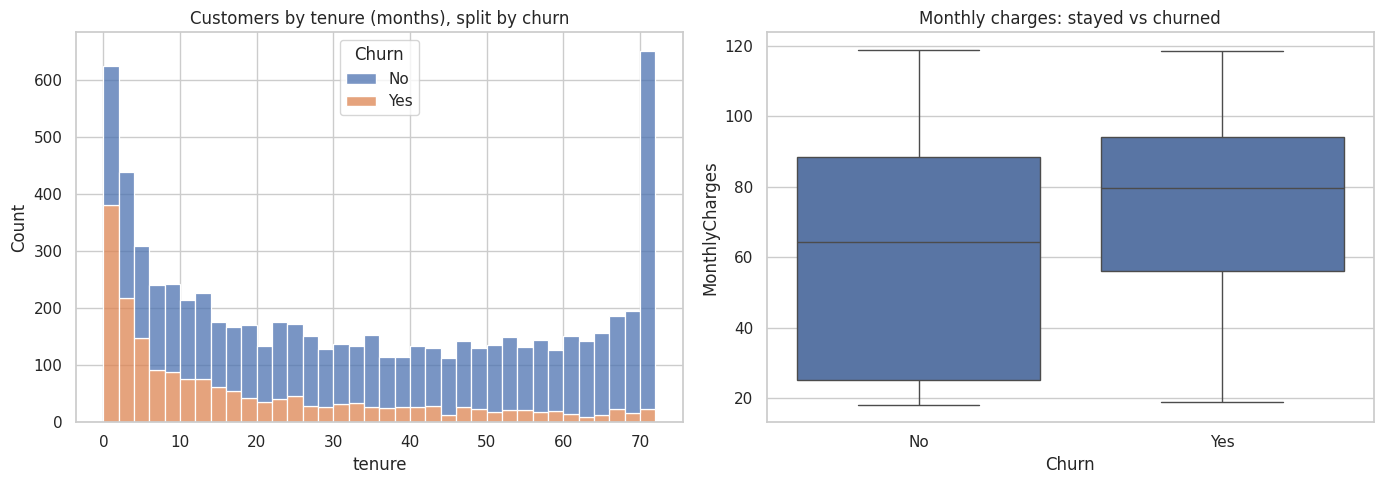

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=ax[0])
ax[0].set_title("Customers by tenure (months), split by churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[1])
ax[1].set_title("Monthly charges: stayed vs churned")
plt.tight_layout(); plt.show()

## 5. Churn model
This cell is the file `03_model.py`. Leakage-safe design: `monthly_revenue_lost` (built from the target) and `customerID` are excluded; the threshold is chosen on training out-of-fold predictions only; the 20% test set is used once.

In [17]:
"""
03_model.py - churn prediction with a leakage-safe setup.

Design choices (each one is explained in the README):
  * Excluded columns: customerID (ID), Churn / churn_flag (target),
    monthly_revenue_lost (built from the target = leakage),
    tenure_band and senior_label (duplicates of tenure and SeniorCitizen).
  * 80/20 stratified split. The 20% test set is touched ONCE, at the end.
  * The decision threshold is chosen on out-of-fold predictions from the TRAINING set only.
"""
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

SEED = 42
df = pd.read_csv("telco_clean.csv")

drop_cols = ["customerID", "Churn", "churn_flag", "monthly_revenue_lost",
             "tenure_band", "senior_label"]
X = df.drop(columns=drop_cols)
y = df["churn_flag"]
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_addons"]
cat_cols = [c for c in X.columns if c not in num_cols + ["SeniorCitizen"]]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")              # SeniorCitizen (0/1) passes through unchanged

models = {
    "Logistic regression": Pipeline([("pre", pre),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random forest": Pipeline([("pre", pre),
        ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                       class_weight="balanced", random_state=SEED, n_jobs=-1))]),
}

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def metrics_at(y_true, proba, t):
    p = (proba >= t).astype(int)
    return dict(threshold=t, precision=precision_score(y_true, p), recall=recall_score(y_true, p),
                f1=f1_score(y_true, p), flagged=int(p.sum()))

results, fitted, test_proba = [], {}, {}
for name, pipe in models.items():
    oof = cross_val_predict(pipe, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]   # train only
    grid = np.arange(0.20, 0.81, 0.01)
    best_t = max(grid, key=lambda t: f1_score(ytr, (oof >= t).astype(int)))        # F1-optimal on train OOF
    pipe.fit(Xtr, ytr)
    proba = pipe.predict_proba(Xte)[:, 1]
    fitted[name], test_proba[name] = pipe, proba
    row = metrics_at(yte, proba, round(float(best_t), 2))
    row.update(model=name, cv_auc=roc_auc_score(ytr, oof), test_auc=roc_auc_score(yte, proba))
    results.append(row)

res = pd.DataFrame(results)[["model", "cv_auc", "test_auc", "threshold",
                             "precision", "recall", "f1", "flagged"]].round(3)

# Baseline rules on the SAME test set
test_df = df.loc[yte.index]
rules = {
    "Rule: month-to-month contract": (test_df["Contract"] == "Month-to-month"),
    "Rule: month-to-month + fiber optic": (test_df["Contract"] == "Month-to-month")
                                          & (test_df["InternetService"] == "Fiber optic"),
}
rule_rows = []
for name, flag in rules.items():
    p = flag.astype(int)
    rule_rows.append(dict(model=name, precision=precision_score(yte, p), recall=recall_score(yte, p),
                          f1=f1_score(yte, p), flagged=int(p.sum())))
rule_res = pd.DataFrame(rule_rows).round(3)

if __name__ == "__main__":
    pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
    print("Train/test sizes:", len(Xtr), len(Xte), "| test churners:", int(yte.sum()))
    print("\nModels (threshold chosen on training out-of-fold predictions):\n", res.to_string(index=False))
    print("\nRules on the same test set:\n", rule_res.to_string(index=False))


Train/test sizes: 5634 1409 | test churners: 374

Models (threshold chosen on training out-of-fold predictions):
               model  cv_auc  test_auc  threshold  precision  recall    f1  flagged
Logistic regression   0.845     0.842       0.57      0.541   0.730 0.621      505
      Random forest   0.844     0.840       0.47      0.538   0.762 0.631      530

Rules on the same test set:
                              model  precision  recall    f1  flagged
     Rule: month-to-month contract      0.426   0.880 0.574      773
Rule: month-to-month + fiber optic      0.527   0.594 0.558      421


### 5a. Test-set diagnostics for logistic regression (ROC curve and confusion matrix)

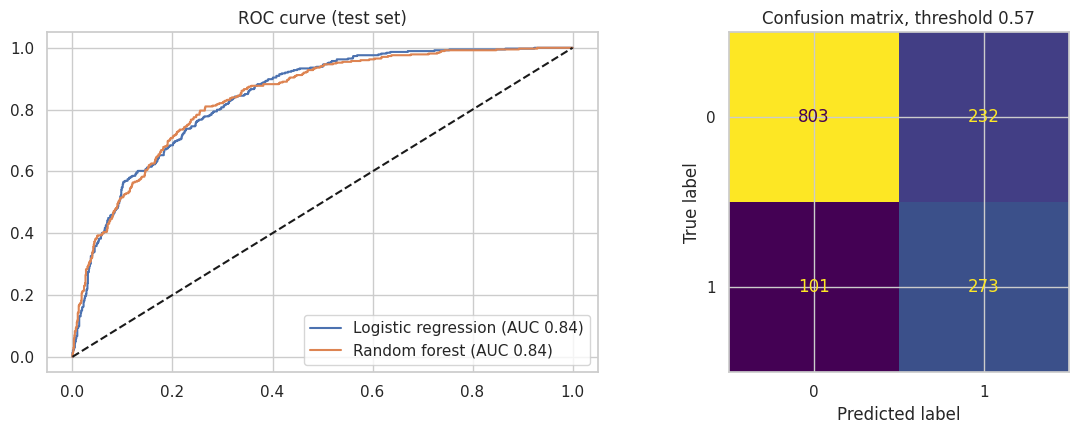

In [18]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
name = "Logistic regression"
thr = float(res.loc[res["model"] == name, "threshold"].iloc[0])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for m in test_proba:
    fpr, tpr, _ = roc_curve(yte, test_proba[m]); ax[0].plot(fpr, tpr, label=f"{m} (AUC {roc_auc_score(yte, test_proba[m]):.2f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curve (test set)"); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(yte, (test_proba[name] >= thr).astype(int), ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix, threshold {thr}")
plt.tight_layout(); plt.show()

### 5b. Gain table: if the retention team contacts only the highest-scored customers (test set)

In [19]:
t = test_df.assign(score=test_proba[name]).sort_values("score", ascending=False)
rows = []
for pct in [10, 20, 30, 40, 50]:
    top = t.head(int(len(t) * pct / 100))
    rows.append(dict(contact_top_pct=pct, customers=len(top),
                     precision_pct=round(top["churn_flag"].mean() * 100, 1),
                     churners_caught_pct=round(top["churn_flag"].sum() / t["churn_flag"].sum() * 100, 1),
                     churned_revenue_caught_pct=round(top["monthly_revenue_lost"].sum() / t["monthly_revenue_lost"].sum() * 100, 1)))
gain = pd.DataFrame(rows); gain

,contact_top_pct,customers,precision_pct,churners_caught_pct,churned_revenue_caught_pct
0,10,140,75.7,28.3,32.1
1,20,281,66.2,49.7,54.3
2,30,422,57.6,65.0,69.6
3,40,563,51.5,77.5,81.8
4,50,704,46.3,87.2,88.7


### 5c. What drives the model? Permutation importance on the test set (original columns)

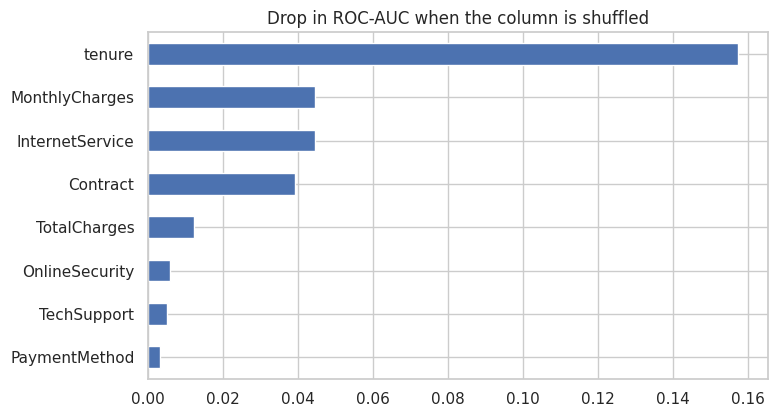

tenure             0.157
MonthlyCharges     0.045
InternetService    0.045
Contract           0.039
TotalCharges       0.013
OnlineSecurity     0.006
TechSupport        0.005
PaymentMethod      0.003
dtype: float64

In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(fitted[name], Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).head(8)
imp.sort_values().plot.barh(title="Drop in ROC-AUC when the column is shuffled", figsize=(8, 4.5)); plt.show()
imp.round(3)

## 6. Risk tiers for the dashboard
Every customer gets a score from **out-of-fold** predictions (each customer is scored by a model that never saw them). High = top 20% of scores, Medium = next 30%, Low = bottom 50%.

In [21]:
oof_all = cross_val_predict(models[name], X, y, cv=cv, method="predict_proba")[:, 1]
out = df.copy()
out["churn_risk_score"] = oof_all.round(4)                  # rounded only for display in the file
rank = pd.Series(oof_all, index=out.index).rank(pct=True, method="first")   # rank on the UNROUNDED score
out["risk_tier"] = pd.cut(rank, [0, 0.5, 0.8, 1.0], labels=["3. Low", "2. Medium", "1. High"]).astype(str)
tiers = (out.groupby("risk_tier")
            .agg(customers=("churn_flag", "size"), churn_pct=("churn_flag", lambda s: round(s.mean() * 100, 1)),
                 monthly_revenue_lost=("monthly_revenue_lost", lambda s: round(s.sum()))))
tiers["pct_of_revenue_lost"] = (tiers["monthly_revenue_lost"] / out["monthly_revenue_lost"].sum() * 100).round(1)
out.to_csv("telco_dashboard.csv", index=False)   # use THIS file in Looker Studio
tiers

,customers,churn_pct,monthly_revenue_lost,pct_of_revenue_lost
risk_tier,,,,
1. High,1409,67.7,77396,55.6
2. Medium,2113,32.1,46517,33.4
3. Low,3521,6.7,15218,10.9


## 7. Findings (auto-generated from the data above)

In [22]:
mtm_f = df[(df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic")]
g = lambda c: df.groupby(c)["churn_flag"].mean().mul(100).round(1)
print(f"1. Churn rate {df.churn_flag.mean()*100:.1f}% ({df.churn_flag.sum():,} of {len(df):,} customers); "
      f"${df.monthly_revenue_lost.sum():,.0f} of ${df.MonthlyCharges.sum():,.0f} monthly revenue "
      f"({df.monthly_revenue_lost.sum()/df.MonthlyCharges.sum()*100:.1f}%) walked away.")
print(f"2. Contract: month-to-month {g('Contract')['Month-to-month']}% vs two-year {g('Contract')['Two year']}%; "
      f"month-to-month holds {df[df.Contract=='Month-to-month'].churn_flag.sum()/df.churn_flag.sum()*100:.1f}% of all churners.")
print(f"3. Month-to-month + fiber optic: {len(mtm_f):,} customers ({len(mtm_f)/len(df)*100:.1f}%), "
      f"churn {mtm_f.churn_flag.mean()*100:.1f}%, {mtm_f.churn_flag.sum()/df.churn_flag.sum()*100:.1f}% of churners, "
      f"{mtm_f.monthly_revenue_lost.sum()/df.monthly_revenue_lost.sum()*100:.1f}% of lost monthly revenue.")
print(f"4. Tenure: {g('tenure_band')['1. 0-12 months']}% churn in the first year vs {g('tenure_band')['4. 49-72 months']}% after 4 years.")
print(f"5. Electronic check {g('PaymentMethod')['Electronic check']}% vs credit card (automatic) {g('PaymentMethod')['Credit card (automatic)']}%.")
print(f"6. Add-ons (internet customers): {df[(df.InternetService!='No')&(df.num_addons==0)].churn_flag.mean()*100:.1f}% churn with 0 add-ons "
      f"vs {df[(df.InternetService!='No')&(df.num_addons==6)].churn_flag.mean()*100:.1f}% with all 6.")
print("7. Model:", res[["model", "test_auc", "precision", "recall"]].to_dict("records"))

1. Churn rate 26.5% (1,869 of 7,043 customers); $139,131 of $456,117 monthly revenue (30.5%) walked away.
2. Contract: month-to-month 42.7% vs two-year 2.8%; month-to-month holds 88.6% of all churners.
3. Month-to-month + fiber optic: 2,128 customers (30.2%), churn 54.6%, 62.2% of churners, 72.2% of lost monthly revenue.
4. Tenure: 47.4% churn in the first year vs 9.5% after 4 years.
5. Electronic check 45.3% vs credit card (automatic) 15.2%.
6. Add-ons (internet customers): 52.2% churn with 0 add-ons vs 5.3% with all 6.
7. Model: [{'model': 'Logistic regression', 'test_auc': 0.842, 'precision': 0.541, 'recall': 0.73}, {'model': 'Random forest', 'test_auc': 0.84, 'precision': 0.538, 'recall': 0.762}]


## 8. Recommendations
- Target the month-to-month + fiber optic group first, and offer a discounted 1- or 2-year contract.
- Add early-life care for the first 12 months, when churn is highest.
- Encourage automatic payment instead of electronic check.
- Bundle tech support and online security for internet customers.
- Use the risk score to call the High tier first, then work down by capacity.

**Limitations:** one public dataset, one snapshot in time, associations are not causes, the churn flag does not say why a customer left, and no cost data is available for retention offers.